## **DataFrame**

Vamos simular uma plataforma de streaming com:

* **Catálogo:**  10 filmes de gêneros variados

* **Usuários:** 50  identificados por user_ID (U001 a U050)

* **Avaliações** Cada usuário avalia apenas alguns filmes (entre 3 e 8), simulando esparsidade realista (~75% de valores ausentes)

* **Ratings** 1 a 5

In [1]:
import pandas as pd
import numpy as np

# ============================================================
# 1. DEFINIÇÃO DOS FILMES
# ============================================================
filmes = [
    'Star Wars',           # Ficção Científica
    'Matrix',              # Ficção Científica
    'Interestelar',        # Ficção Científica
    'Titanic',             # Romance
    'Diário de uma Paixão',# Romance
    'O Poderoso Chefão',   # Drama
    'Pulp Fiction',        # Drama
    'Toy Story',           # Animação
    'Procurando Nemo',     # Animação
    'O Iluminado'          # Terror
]

# Perfis de gosto por gênero (para gerar ratings coerentes)
perfis_genero = {
    'Ficção Científica': ['Star Wars', 'Matrix', 'Interestelar'],
    'Romance':           ['Titanic', 'Diário de uma Paixão'],
    'Drama':             ['O Poderoso Chefão', 'Pulp Fiction'],
    'Animação':          ['Toy Story', 'Procurando Nemo'],
    'Terror':            ['O Iluminado']
}

In [2]:
# ============================================================
# 2. GERAÇÃO DOS RATINGS COM PERFIS DE GOSTO
# ============================================================
np.random.seed(42)

# Cada usuário tem um gênero favorito e um secundário
generos = list(perfis_genero.keys())
usuarios = [f'U{i:03d}' for i in range(1, 51)]  # U001 a U050

# Matriz de ratings (NaN = não avaliado)
matriz_ratings = pd.DataFrame(
    np.nan,
    index=usuarios,
    columns=filmes
)

for user_id in usuarios:
    # Sorteia gênero favorito e secundário
    genero_fav = np.random.choice(generos)
    genero_sec = np.random.choice([g for g in generos if g != genero_fav])

    # Sorteia quantos filmes vai avaliar (entre 3 e 8)
    n_avaliacoes = np.random.randint(3, 9)

    # Sorteia quais filmes avaliar
    filmes_avaliados = np.random.choice(filmes, size=n_avaliacoes, replace=False)

    for filme in filmes_avaliados:
        # Determina se o filme pertence ao gênero favorito/secundário
        if filme in perfis_genero[genero_fav]:
            nota = np.random.choice([4, 5], p=[0.4, 0.6])
        elif filme in perfis_genero[genero_sec]:
            nota = np.random.choice([3, 4, 5], p=[0.3, 0.4, 0.3])
        else:
            nota = np.random.choice([1, 2, 3, 4], p=[0.2, 0.3, 0.3, 0.2])

        matriz_ratings.loc[user_id, filme] = nota



In [3]:
print("DataFrame de ratings (primeiras 10 linhas):")
print(matriz_ratings.head(10))



DataFrame de ratings (primeiras 10 linhas):
      Star Wars  Matrix  Interestelar  Titanic  Diário de uma Paixão  \
U001        3.0     NaN           NaN      1.0                   NaN   
U002        NaN     NaN           2.0      NaN                   NaN   
U003        2.0     2.0           NaN      3.0                   NaN   
U004        NaN     3.0           NaN      4.0                   1.0   
U005        3.0     4.0           1.0      4.0                   5.0   
U006        NaN     1.0           NaN      2.0                   4.0   
U007        3.0     3.0           NaN      4.0                   2.0   
U008        NaN     4.0           NaN      NaN                   5.0   
U009        3.0     4.0           4.0      NaN                   NaN   
U010        NaN     4.0           NaN      NaN                   NaN   

      O Poderoso Chefão  Pulp Fiction  Toy Story  Procurando Nemo  O Iluminado  
U001                4.0           NaN        NaN              5.0          3.0  
U

In [4]:
matriz_ratings.index

Index(['U001', 'U002', 'U003', 'U004', 'U005', 'U006', 'U007', 'U008', 'U009',
       'U010', 'U011', 'U012', 'U013', 'U014', 'U015', 'U016', 'U017', 'U018',
       'U019', 'U020', 'U021', 'U022', 'U023', 'U024', 'U025', 'U026', 'U027',
       'U028', 'U029', 'U030', 'U031', 'U032', 'U033', 'U034', 'U035', 'U036',
       'U037', 'U038', 'U039', 'U040', 'U041', 'U042', 'U043', 'U044', 'U045',
       'U046', 'U047', 'U048', 'U049', 'U050'],
      dtype='object')

In [5]:
# Estatísticas
total = matriz_ratings.shape[0] * matriz_ratings.shape[1]
ausentes = matriz_ratings.isna().sum().sum()
print(f"\n Total de células: {total}")
print(f" Ratings observados: {total - ausentes}")
print(f" Esparsidade: {ausentes / total:.1%}")


 Total de células: 500
 Ratings observados: 275
 Esparsidade: 45.0%


## **Visualização da esparsidade**

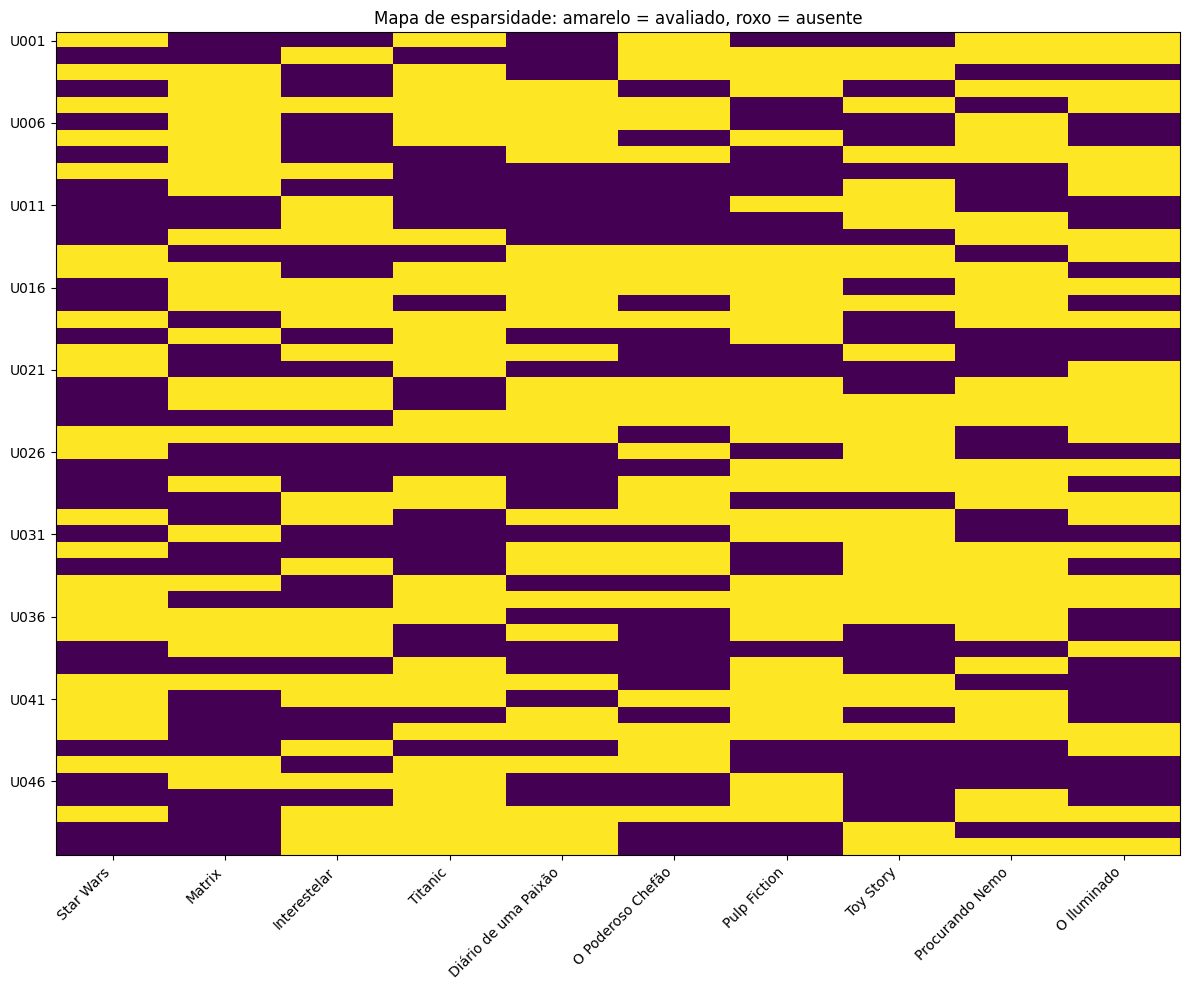

In [6]:
import matplotlib.pyplot as plt

# Mapa de calor: amarelo = avaliado, roxo = ausente
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(~matriz_ratings.isna().values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(filmes)))
ax.set_xticklabels(filmes, rotation=45, ha='right')
ax.set_yticks(range(0, 50, 5))
ax.set_yticklabels(usuarios[::5])
ax.set_title('Mapa de esparsidade: amarelo = avaliado, roxo = ausente')
plt.tight_layout()
plt.show()

## **Implementação do FUNKSVD**


O código a seguir implementa o algoritmo FunkSVD (também conhecido como Regularized Matrix Factorization), que consiste em uma técnica clássica de Filtragem Colaborativa para sistemas de recomendação. A ideia central é decompor a matriz de avaliações (usuários $x$ itens) em dois fatores latentes menores, aprendendo apenas sobre os valores observados (diferente do SVD tradicional que exige matriz completa).

### **Em alto nível tem-se:**
Imagine que cada usuário e cada filme têm um "perfil secreto" de k=20 números (gosto por ação, romance, humor, etc.). O FunkSVD:

1. Começa com perfis aleatórios.

2. Para cada nota conhecida, calcula o quão errado o modelo está.

3. Ajusta os perfis de usuário e item na direção que reduz esse erro, com um freio (regularização) para não exagerar.

4. Repete 100 vezes até os perfis ficarem bons.

5. Usa esses perfis para prever notas desconhecidas.






In [7]:
class FunkSVD:
    """
    Fatoração de matrizes com SGD para sistemas de recomendação.
    Aprende fatores latentes apenas sobre valores observados.
    """
    def __init__(self, n_users, n_items, k=10, eta=0.01, lam=0.05, epochs=100):
        self.k = k
        self.eta = eta          # taxa de aprendizado
        self.lam = lam          # regularização
        self.epochs = epochs
        self.n_users = n_users
        self.n_items = n_items

        np.random.seed(42)
        self.P = np.random.normal(0, 0.1, (n_users, k))   # fatores de usuário
        self.Q = np.random.normal(0, 0.1, (n_items, k))   # fatores de item
        self.b_u = np.zeros(n_users)                      # viés de usuário
        self.b_i = np.zeros(n_items)                      # viés de item
        self.mu = 0.0                                     # média global
        self.historico = []                               # RMSE por época

    def fit(self, dados, verbose=True):
        """Treina o modelo com SGD sobre os dados observados."""
        self.mu = np.mean([r for _, _, r in dados])

        for epoch in range(self.epochs):
            np.random.shuffle(dados)  # embaralhar é essencial em SGD
            erro_total = 0.0

            for u, i, r in dados:
                # Previsão
                pred = self.mu + self.b_u[u] + self.b_i[i] + self.P[u] @ self.Q[i]
                e = r - pred
                erro_total += e ** 2

                # Atualizações SGD com regularização
                self.b_u[u] += self.eta * (e - self.lam * self.b_u[u])
                self.b_i[i] += self.eta * (e - self.lam * self.b_i[i])
                self.P[u]   += self.eta * (e * self.Q[i] - self.lam * self.P[u])
                self.Q[i]   += self.eta * (e * self.P[u] - self.lam * self.Q[i])

            rmse = np.sqrt(erro_total / len(dados))
            self.historico.append(rmse)

            if verbose and (epoch + 1) % 20 == 0:
                print(f"Época {epoch+1:3d} | RMSE treino: {rmse:.4f}")

    def prever(self, u, i):
        """Previsão para um par (usuário, item)."""
        return self.mu + self.b_u[u] + self.b_i[i] + self.P[u] @ self.Q[i]

## **Preparação dos dadoso**

In [8]:
def df_para_lista(df):
    """Converte DataFrame em lista de tuplas (u_idx, i_idx, rating)."""
    dados = []
    for u_idx, user_id in enumerate(df.index):
        for i_idx, filme in enumerate(df.columns):

            #u_idx-> indice do usuário
            #i_idx-> indice do filme
            r = df.iloc[u_idx, i_idx] ##rating  do filme para cada usuario
            if not np.isnan(r):
                # Se o rating é não nulo, então devolvemos uma relaçao (linha, colua, raitinhg)
                dados.append((u_idx, i_idx, r))
    return dados



In [9]:
matriz_ratings.loc['U001']

,U001
Star Wars,3.0
Matrix,NaN
Interestelar,NaN
Titanic,1.0
Diário de uma Paixão,NaN
O Poderoso Chefão,4.0
Pulp Fiction,NaN
Toy Story,NaN
Procurando Nemo,5.0
O Iluminado,3.0


In [10]:
dados = df_para_lista(matriz_ratings)

## **Treinamento**

In [11]:
# número de usuários
matriz_ratings.shape[0]

50

In [12]:
# número de filmes
matriz_ratings.shape[1]

10

In [13]:

print("\n" + "=" * 60)
print("TREINAMENTO DO FUNKSVD")
print("=" * 60)

modelo = FunkSVD(
    n_users=matriz_ratings.shape[0],
    n_items=matriz_ratings.shape[1],
    k=10,          # fatores latentes
    eta=0.01,      # taxa de aprendizado
    lam=0.05,      # regularização
    epochs=200     # épocas
)

modelo.fit(dados)


TREINAMENTO DO FUNKSVD
Época  20 | RMSE treino: 1.0979
Época  40 | RMSE treino: 0.7187
Época  60 | RMSE treino: 0.3862
Época  80 | RMSE treino: 0.2440
Época 100 | RMSE treino: 0.1831
Época 120 | RMSE treino: 0.1579
Época 140 | RMSE treino: 0.1445
Época 160 | RMSE treino: 0.1380
Época 180 | RMSE treino: 0.1342
Época 200 | RMSE treino: 0.1310


## **FUNÇÃO DE RECOMENDAÇÃO**

In [14]:
def recomendar_filmes(df_original, modelo, user_id, top_n=5,
                      excluir_ja_vistos=True):
    """
    Recomenda os top-N filmes para um usuário.

    Parâmetros:
    - df_original: DataFrame com ratings originais (NaN = não avaliado)
    - modelo: FunkSVD treinado
    - user_id: ID do usuário (ex.: 'U001')
    - top_n: número de recomendações
    - excluir_ja_vistos: se True, não recomenda filmes já avaliados
    """
    if user_id not in df_original.index:
        raise ValueError(f"Usuário {user_id} não encontrado.")

    u_idx = df_original.index.get_loc(user_id)
    filmes = df_original.columns.tolist()
    ratings_usuario = df_original.loc[user_id].values

    candidatos = []
    for i_idx, filme in enumerate(filmes):
        # Pular filmes já avaliados (se solicitado)
        if excluir_ja_vistos and not np.isnan(ratings_usuario[i_idx]):
            continue

        pred = modelo.prever(u_idx, i_idx)
        # Limitar previsão ao intervalo válido [1, 5]
        pred = np.clip(pred, 1.0, 5.0)
        candidatos.append((filme, pred))

    # Ordenar por nota prevista (decrescente)
    candidatos.sort(key=lambda x: x[1], reverse=True)
    return candidatos[:top_n]

## **RECOMENDSAÇÕES PERSONALIZADA**

In [15]:
# Escolher 5 usuários representativos
usuarios_demo = ['U001', 'U010', 'U020', 'U035', 'U050']

for user_id in usuarios_demo:
    # Mostrar o que o usuário já avaliou
    avaliados = matriz_ratings.loc[user_id].dropna()
    print(f"\n{'─' * 60}")
    print(f" Usuário: {user_id}")
    print(f"{'─' * 60}")
    print("  Já avaliou:")
    for filme, nota in avaliados.items():
        print(f"     • {filme}: {int(nota)}")

    # Recomendações
    recs = recomendar_filmes(matriz_ratings, modelo, user_id, top_n=5)
    print("\n Recomendações (FunkSVD):")
    for rank, (filme, nota) in enumerate(recs, 1):
        print(f"     {rank}. {filme} → nota prevista: {nota:.2f}")


────────────────────────────────────────────────────────────
 Usuário: U001
────────────────────────────────────────────────────────────
  Já avaliou:
     • Star Wars: 3
     • Titanic: 1
     • O Poderoso Chefão: 4
     • Procurando Nemo: 5
     • O Iluminado: 3

 Recomendações (FunkSVD):
     1. Toy Story → nota prevista: 3.59
     2. Diário de uma Paixão → nota prevista: 3.04
     3. Pulp Fiction → nota prevista: 2.99
     4. Interestelar → nota prevista: 2.79
     5. Matrix → nota prevista: 2.64

────────────────────────────────────────────────────────────
 Usuário: U010
────────────────────────────────────────────────────────────
  Já avaliou:
     • Matrix: 4
     • Toy Story: 3
     • O Iluminado: 2

 Recomendações (FunkSVD):
     1. Star Wars → nota prevista: 3.45
     2. Titanic → nota prevista: 3.35
     3. Diário de uma Paixão → nota prevista: 3.26
     4. Interestelar → nota prevista: 3.23
     5. O Poderoso Chefão → nota prevista: 3.00

──────────────────────────────────